# M08-3 | What XnnpackPartitioner Does Not Take: How the Graph Is Split and What the Boundary Looks Like

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/en/m08_xnnpack_executorch/03_unsupported_ops.ipynb)

The partitioner finds the connected subgraphs the backend can handle and compiles each into one delegate; ops it cannot handle stay on the graph and are run by ExecuTorch's own portable kernels (generic C++ implementations).
In M08-2, TinyConvNet's whole graph went into XNNPACK. Here we deliberately put a `cumsum` between two convs: XNNPACKQuantizer does not annotate it, and XnnpackPartitioner does not take it either (measured on executorch 1.5.0).

- **A.** Quantization: `cumsum` has no annotation and runs fp32 on the Q/DQ graph.
- **B.** Lowering: the graph is split into two delegates before and after `cumsum`, and fp32 is passed between the two.
- **C.** Execution: how far the `.pte` output is from the Q/DQ graph's.

This notebook needs executorch (`uv sync --group executorch`).

In [1]:
#| include: false
# On Google Colab: download this tutorial's code and install the packages (takes a few minutes the first time).
# On your own machine (see the README for the environment), this cell does nothing.
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "executorch==1.5.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # let the notebook import this tutorial's common/
    os.chdir(f"{repo}/en/m08_xnnpack_executorch")

In [2]:
import torch
import torch.nn as nn

from common.pt2e import quiet  # must be imported before executorch
from common.env import env_summary
from common.executorch_utils import PteRunner, delegation_summary, lower_to_xnnpack, xnnpack_ptq
from common.graph_utils import op_counts, short
from common.models import example_inputs
from common.pt2e import get_xnnpack_quantizer, export_module
from common.viz import annotation_notes, draw, table

quiet()
_ = torch.manual_seed(0)
print(env_summary())

Linux x86_64 | torch 2.14.0+cu130 | threads=4 | mkldnn=True | nnpack=True


In [3]:
class ConvCumsumConv(nn.Module):
    """conv → relu → cumsum → conv. cumsum accumulates along the channel dimension."""

    def __init__(self, ch=8):
        super().__init__()
        self.conv1 = nn.Conv2d(3, ch, 3, padding=1)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)

    def forward(self, x):
        y = torch.relu(self.conv1(x))
        y = torch.cumsum(y, dim=1)
        return self.conv2(y)


model = ConvCumsumConv().eval()
x = example_inputs(1)

## A. Quantization: `cumsum` Has No Annotation

First look at the annotations only: after export, call the executorch XNNPACKQuantizer's `annotate`, and draw the annotations under the nodes (M03-2):

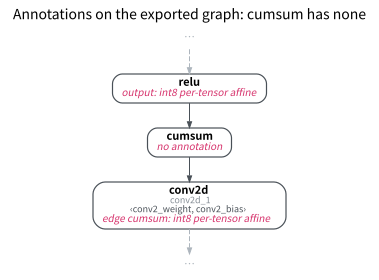

In [4]:
labeled = export_module(model, x, dynamic_batch=False)
get_xnnpack_quantizer("executorch", is_per_channel=True)[0].annotate(labeled)
notes = annotation_notes(labeled, unlabeled=True)
draw(labeled, focus=["relu", "cumsum", "conv2d_1"], hops=0,
     notes={k: notes[k] for k in ["relu", "cumsum"]} | {"conv2d_1": notes["conv2d_1"].split("\n")[0]},
     title="Annotations on the exported graph: cumsum has none")

XNNPACKQuantizer has no annotator for cumsum, so cumsum has no annotation (the fallback from M03-6). Its upstream and downstream do: relu's output must be quantized (the output of conv-relu), and conv2d_1's input edge must be quantized.
After PTQ (`xnnpack_ptq`, M08-2), there is one q/dq pair on each side of cumsum:

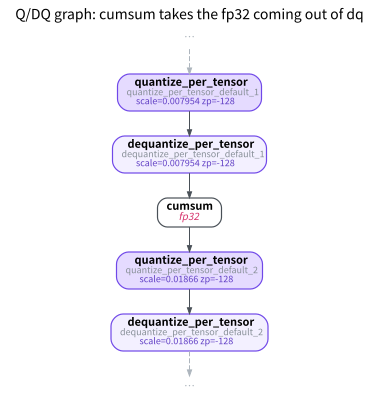

In [5]:
qdq = xnnpack_ptq(model, x)
draw(qdq, focus="cumsum", hops=2, notes={"cumsum": "fp32"}, title="Q/DQ graph: cumsum takes the fp32 coming out of dq")

cumsum takes the fp32 coming out of dequantize, outputs fp32, and that is quantized again for conv2d_1.

## B. Lowering: the Graph Is Split into Two Delegates

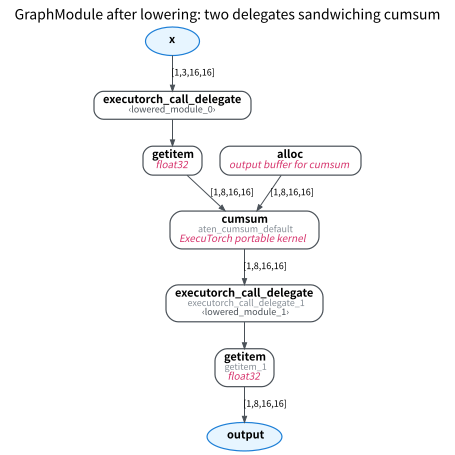

In [6]:
edge, pte = lower_to_xnnpack(qdq, x)  # this project's wrapper: export → to_edge_transform_and_lower → to_executorch (M08-2 A)
lowered = edge.exported_program().graph_module
draw(lowered, show_shapes=True,
     notes={"aten_cumsum_default": "ExecuTorch portable kernel", "alloc": "output buffer for cumsum",
            **{n.name: str(n.meta["val"].dtype).removeprefix("torch.") for n in lowered.graph.nodes
               if short(n.target) == "getitem"}},
     title="GraphModule after lowering: two delegates sandwiching cumsum")

Look between the two `executorch_call_delegate`s: a `getitem` pulls out the previous block's output and passes it to cumsum, and cumsum's output goes into the next block. The edges are labeled with shapes, and under `getitem` is the dtype of its output (taken from `node.meta["val"]`): float32.
The dq and q around cumsum were absorbed into the delegates on either side: the previous block ends by converting int8 back to fp32, and the next block starts by converting to int8 again.

`alloc` is the output buffer that `to_executorch()` set up for cumsum ahead of time (memory planning, M08-2 C), and `getitem` takes a value from the delegate's output tuple; neither is a computation.

Count where each op went with `delegation_summary`:

In [7]:
n_sub, n_del, n_non, by_op = delegation_summary(edge)
table([[op, d, nd] for op, (d, nd) in sorted(by_op.items())], ["op (Edge dialect name)", "handed to XNNPACK", "stays in ExecuTorch"])

op (Edge dialect name),handed to XNNPACK,stays in ExecuTorch
alloc,0,1
aten_convolution_default,2,0
aten_cumsum_default,0,1
aten_relu_default,1,0
getitem,0,2
quantized_decomposed_dequantize_per_channel_default,2,0
quantized_decomposed_dequantize_per_tensor_default,4,0
quantized_decomposed_quantize_per_tensor_default,4,0


In [8]:
n_before = sum(op_counts(qdq).values())
left = {op: nd for op, (_, nd) in by_op.items() if nd}
print(f"delegates: {n_sub}; of the Q/DQ graph's {n_before} ops, {n_del} went into a delegate; left behind: {left}")
assert n_sub == 2 and n_del == n_before - 1 and set(left) == {"aten_cumsum_default", "alloc", "getitem"}
assert all(n.meta["val"].dtype == torch.float32 for n in lowered.graph.nodes if short(n.target) == "getitem")  # fp32 across the boundary

delegates: 2; of the Q/DQ graph's 14 ops, 13 went into a delegate; left behind: {'getitem': 2, 'alloc': 1, 'aten_cumsum_default': 1}


On the Q/DQ graph only cumsum did not go into a delegate; the rest of what is left behind, `alloc` and `getitem`, were added by lowering.
Every extra boundary means one more int8 ↔ fp32 conversion, and one more round trip between ExecuTorch and XNNPACK.

Before quantizing, use the annotations to confirm "which ops were not annotated" (M03-2); before deployment, use this table to confirm "which ops did not go into a delegate". The two are independent decisions:

| Who decides | When unsupported |
|---|---|
| whether the quantizer annotates | An unannotated op runs fp32 on the Q/DQ graph |
| whether the partitioner takes it | An op it does not take stays outside the delegate and runs ExecuTorch's portable kernel |

## C. Execution: the `.pte` vs the Q/DQ Graph's Output

The `.pte` accepts only the batch 1 it was exported with (M08-2 C), so the 64 random inputs are fed one at a time:

In [9]:
runner = PteRunner(pte)
xs = torch.randn(64, 3, 16, 16)
with torch.no_grad():
    y_pte = torch.cat([runner(xs[i : i + 1]) for i in range(len(xs))])
    y_qdq = torch.cat([qdq(xs[i : i + 1]) for i in range(len(xs))])
lsb = [n for n in qdq.graph.nodes if short(n.target) == "quantize_per_tensor"][-1].args[1]
same = (y_pte == y_qdq).float().mean().item()
max_lsb = ((y_pte - y_qdq).abs() / lsb).round().max().item()
print(f"Bit-identical outputs: {same:.2%}; max difference {max_lsb:.0f} output LSB (output LSB = scale of the last quantize, {lsb:.4g})")

Bit-identical outputs: 99.68%; max difference 1 output LSB (output LSB = scale of the last quantize, 0.01771)


In [10]:
assert max_lsb <= 2

Split into two blocks, it still runs. The difference from the Q/DQ graph is only a few output LSB, coming from the rounding of the integer kernels (M08 overview, "Numerical Differences from the Q/DQ Graph").
Unsupported ops do not make the export fail; that segment just does not run on XNNPACK.

## Summary

- Ops the quantizer does not annotate run fp32; ops the partitioner does not take stay outside the delegate and run ExecuTorch's portable kernels.
- An unsupported op in the middle splits the graph, fp32 is passed across the boundary, and extra int8 ↔ fp32 conversions and runtime round trips appear.
- Before deployment, use `get_delegation_info` (`delegation_summary`) to confirm which ops did not go into a delegate.